Task 1: Temperature 

In [24]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from frost_id import client_id

client_id = client_id

#Requests the daily mean air temperture for all of 2025
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
data = r.json()


Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis


In [25]:
observations = data["data"]

df = pd.DataFrame(observations)

df.head()

df["temperature"] = df["observations"].apply(
    lambda x: x[0]["value"]
)

df["time"] = pd.to_datetime(df["referenceTime"])

df.head()

df["temperature"] = df["observations"].apply(
    lambda x: x[0]["value"]
)

df["time"] = pd.to_datetime(df["referenceTime"])

df.head()

,sourceId,referenceTime,observations,temperature,time
0,SN17850:0,2025-01-01T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-5.2,2025-01-01 00:00:00+00:00
1,SN17850:0,2025-01-02T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-11.5,2025-01-02 00:00:00+00:00
2,SN17850:0,2025-01-03T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-8.9,2025-01-03 00:00:00+00:00
3,SN17850:0,2025-01-04T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-15.5,2025-01-04 00:00:00+00:00
4,SN17850:0,2025-01-05T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-12.5,2025-01-05 00:00:00+00:00


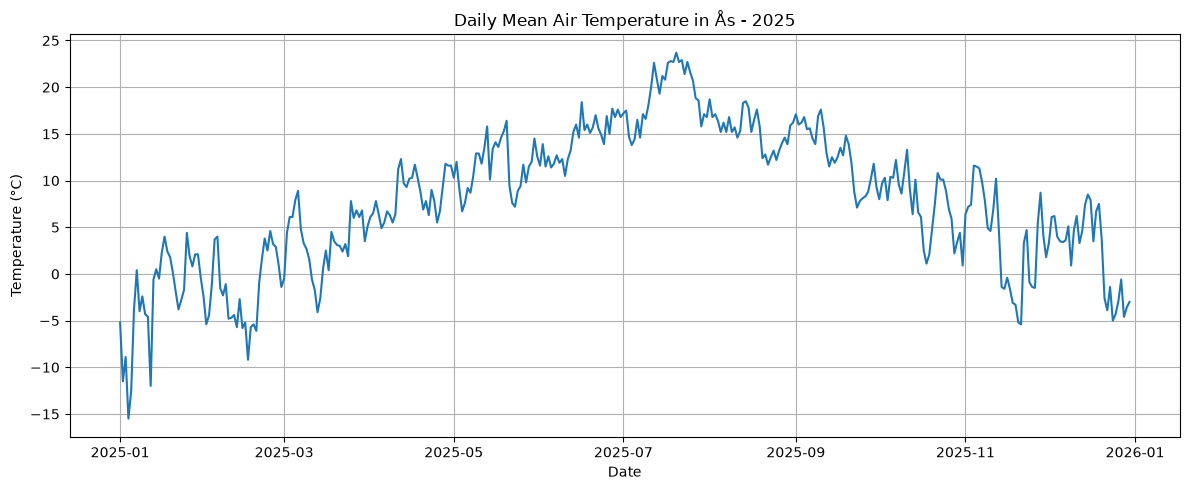

In [26]:

plt.figure(figsize=(12, 5))

plt.plot(df["time"], df["temperature"])

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås - 2025")

plt.grid(True)
plt.tight_layout()
plt.show()

Create a nicely formatted summary table containing mean, median, min and max
temperature for this year, and display it with print()

In [27]:
summary = {
    "Mean": df["temperature"].mean(),
    "Median": df["temperature"].median(),
    "Min": df["temperature"].min(),
    "Max": df["temperature"].max()
}

print(summary)

{'Mean': np.float64(7.902747252747254), 'Median': np.float64(8.4), 'Min': np.float64(-15.5), 'Max': np.float64(23.7)}


In [28]:
summary_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max"],
    "Temperature (°C)": [
        df["temperature"].mean(),
        df["temperature"].median(),
        df["temperature"].min(),
        df["temperature"].max()
    ]
})

print(summary_table)

  Statistic  Temperature (°C)
0      Mean          7.902747
1    Median          8.400000
2       Min        -15.500000
3       Max         23.700000


Task 2: Combined graph

In [ ]:
#Requests the daily mean air temperture for all of 2025
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D), sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, params=parameters, auth=(client_id,''))


#Sortere og hente ut dataene hver for seg?
# Extract JSON data
precipitation_json = r.json()

#Precipitation to a Pandas dataframe 
precipitation_data = pd.DataFrame(precipitation_json["data"])

# Get the data from whereever it is placed in the data (in observations)
precipitation_data["precipitation"] = precipitation_data["observations"].apply(
    lambda x: x[0]["value"])

#tid (Reference time) må konverteres tik Datetime
# 
precipitation_data["time"] = pd.to_datetime(precipitation_data["referenceTime"])

#Temperaturdata ligger i Deliverable 1. Kan vel refereres til derfra senere når det limes inn
#df[time] og df[temperature]

# Kombinere dataene før plotting? Må fikses etter at den legges til under task 1
Combined_data = pd.merge(df[["time","temperature"]], precipitation_data[["time","precipitation"]], on="time")

print(Combined_data)


                         time  temperature  precipitation
0   2025-01-01 00:00:00+00:00         -5.2           -5.2
1   2025-01-02 00:00:00+00:00        -11.5          -11.5
2   2025-01-03 00:00:00+00:00         -8.9           -8.9
3   2025-01-04 00:00:00+00:00        -15.5          -15.5
4   2025-01-05 00:00:00+00:00        -12.5          -12.5
..                        ...          ...            ...
359 2025-12-26 00:00:00+00:00         -2.9           -2.9
360 2025-12-27 00:00:00+00:00         -0.6           -0.6
361 2025-12-28 00:00:00+00:00         -4.6           -4.6
362 2025-12-29 00:00:00+00:00         -3.6           -3.6
363 2025-12-30 00:00:00+00:00         -3.0           -3.0

[364 rows x 3 columns]


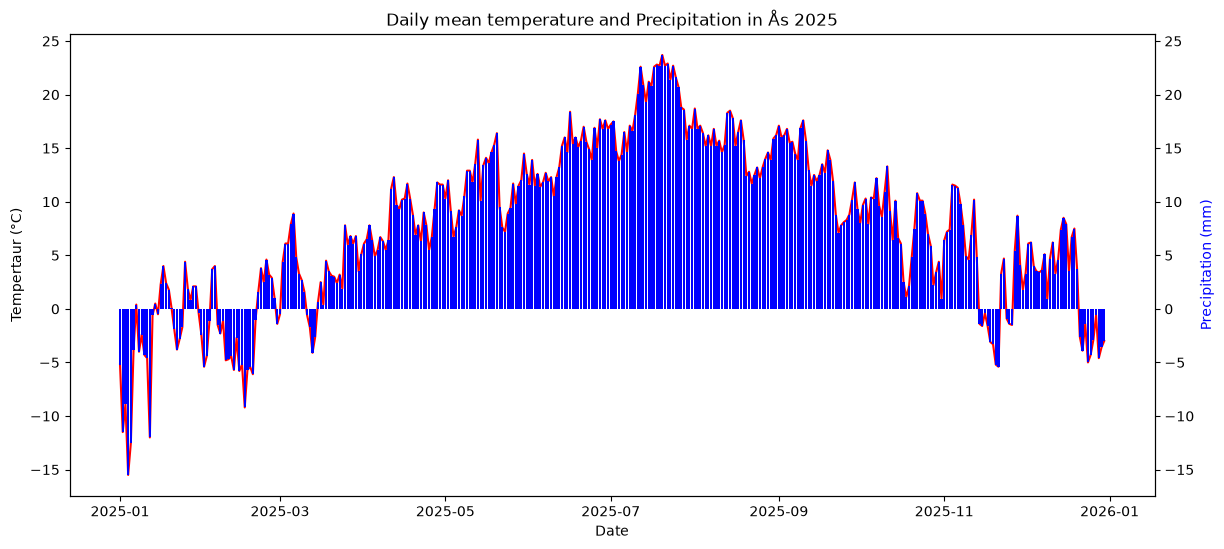

In [42]:
#Plotte ut dataene på nytt. det fra sist bare rot...

# Lager en figur
fig, ax1 = plt.subplots(figsize=(14, 6))

#Plotter temperatur på den første aksen
ax1.plot(Combined_data["time"],
         Combined_data["temperature"],
         color="red")

ax1.set_xlabel("Date")
ax1.set_ylabel("Tempertaur (°C)")

# Enda en akse
ax2 = ax1.twinx()

ax2.bar(Combined_data["time"],
        Combined_data["precipitation"],
        color="blue")

ax2.set_ylabel("Precipitation (mm)", color="blue")

#Tittel på grafen
plt.title("Daily mean temperature and Precipitation in Ås 2025")

plt.show()